# Day 4 – Outlier Detection and Handling
## Holistic Data Preparer | Fintech: Customer Credit Risk Prediction

## 1. Project folder structure

The notebook expects this structure:

```text
Holistic_Data_Preparer/
├── data/
│   ├── raw/
│   ├── interim/
│   └── processed/
├── notebooks/
├── src/
├── reports/
├── screenshots/
├── video/
├── README.md
├── requirements.txt
└── .gitignore
```

Run this notebook from `notebooks/` or the project root. The path helper below searches for the project directory.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
EXPECTED_COLUMNS = [
    "customer_id", "age", "gender", "region", "education_level",
    "employment_type", "annual_income", "loan_amount", "loan_purpose",
    "credit_score", "repayment_history", "transaction_count",
    "spending_ratio", "join_date", "default_flag"
]
NUMERIC_FEATURES = [
    "age", "annual_income", "loan_amount", "credit_score",
    "transaction_count", "spending_ratio"
]

# Locate the project root whether this notebook is run from notebooks/ or root.
candidate_roots = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next((p for p in candidate_roots if (p / "data").exists()), Path.cwd())
RAW_DIR = PROJECT_ROOT / "data" / "raw"
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports"

for folder in [RAW_DIR, INTERIM_DIR, PROCESSED_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT.resolve())

Project root: C:\Users\tejpa\OneDrive\Documents\R & W Projects\Data Preparing & Processing\Holistic-data-preparer


## 2. What is an outlier?

An **outlier** is an observation that is unusually far from the rest of the values in a dataset.

Credit-risk examples:
- Annual income far above most customers.
- A loan amount that is exceptionally large.
- A credit score outside the valid scoring scale.
- A negative transaction count.
- A spending ratio greater than 1 when the field is defined as a proportion.

An unusual value may be:
- A data-entry or measurement error.
- A valid but rare customer profile.
- A sign of a different customer segment.
- A fraud or risk signal that deserves investigation.

**Key lesson:** statistical detection identifies values for review; it does not prove that the values are wrong.

## 3. Load and validate the Day-3-style interim input

In [2]:
raw_path = RAW_DIR / "main_customer_loan_data.csv"
interim_path = INTERIM_DIR / "customer_credit_risk_day03_imputed.csv"

In [3]:
if not raw_path.exists():
    raise FileNotFoundError(
        f"Raw dataset not found: {raw_path}. Place the original CSV in data/raw/."
    )

In [4]:
raw_df = pd.read_csv(raw_path)
print("Raw dataset shape:", raw_df.shape)
print("Raw file:", raw_path)

Raw dataset shape: (5, 9)
Raw file: c:\Users\tejpa\OneDrive\Documents\R & W Projects\Data Preparing & Processing\Holistic-data-preparer\data\raw\main_customer_loan_data.csv


In [5]:
if not interim_path.exists():
    interim_df = raw_df.copy()
    for col in interim_df.select_dtypes(include=np.number).columns:
        if col != "default_flag":
            interim_df[col] = interim_df[col].fillna(interim_df[col].median())
    for col in interim_df.select_dtypes(include="object").columns:
        if col not in ["customer_id", "join_date"]:
            modes = interim_df[col].mode(dropna=True)
            if not modes.empty:
                interim_df[col] = interim_df[col].fillna(modes.iloc[0])
    interim_df.to_csv(interim_path, index=False)
    print("Created fallback interim file:", interim_path)

In [6]:
df = pd.read_csv(interim_path)
missing_columns = sorted(set(EXPECTED_COLUMNS) - set(df.columns))
extra_columns = sorted(set(df.columns) - set(EXPECTED_COLUMNS))
assert not missing_columns, f"Missing expected columns: {missing_columns}"
assert not extra_columns, f"Unexpected columns: {extra_columns}"
assert df["customer_id"].is_unique, "customer_id should uniquely identify records."
assert set(df["default_flag"].dropna().unique()).issubset({0, 1}), "Target must be 0/1."

df["join_date"] = pd.to_datetime(df["join_date"], errors="coerce")
for col in NUMERIC_FEATURES + ["default_flag"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Interim dataset shape:", df.shape)
display(df.head())

Interim dataset shape: (1000, 15)


,customer_id,age,gender,region,education_level,employment_type,annual_income,loan_amount,loan_purpose,credit_score,repayment_history,transaction_count,spending_ratio,join_date,default_flag
0,100001,25.0,Other,West,Postgraduate,Self-employed,567257.078077,203652.899789,Personal,695.653979,Good,35.0,0.245852,2021-01-01,0
1,100002,55.0,Other,North,Postgraduate,Unemployed,549222.003633,357645.215003,Vehicle,621.651638,Average,34.0,0.487278,2021-01-02,0
2,100003,50.0,Male,South,Postgraduate,Salaried,819172.491746,190787.099515,Education,819.857156,Good,29.0,0.272024,2021-01-03,0
3,100004,40.0,Other,South,Postgraduate,Self-employed,830202.917161,245846.946211,Home,730.222607,Average,40.0,0.411828,2021-01-04,1
4,100005,40.0,Female,West,Postgraduate,Self-employed,532280.826257,76055.814034,Personal,661.062092,Good,31.0,0.188984,2021-01-05,0


## 4. Select appropriate numeric fields

In [7]:
df[NUMERIC_FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
age,1000.0,43.002000,12.657812,21.000000,32.000000,43.000000,54.000000,6.500000e+01
annual_income,1000.0,660601.833453,203510.961769,120000.000000,528271.540725,658337.320380,795757.428869,1.329473e+06
loan_amount,1000.0,249673.919402,106672.172567,20000.000000,174546.638535,246683.696185,315499.589976,6.299451e+05
credit_score,1000.0,694.720152,72.418906,360.816406,649.089913,695.653979,739.031894,9.000000e+02
transaction_count,1000.0,35.172000,5.995195,16.000000,31.000000,35.000000,39.000000,5.600000e+01
spending_ratio,1000.0,0.301480,0.157988,0.014376,0.185099,0.281860,0.393109,8.811201e-01


## 5. Visual detection using boxplots

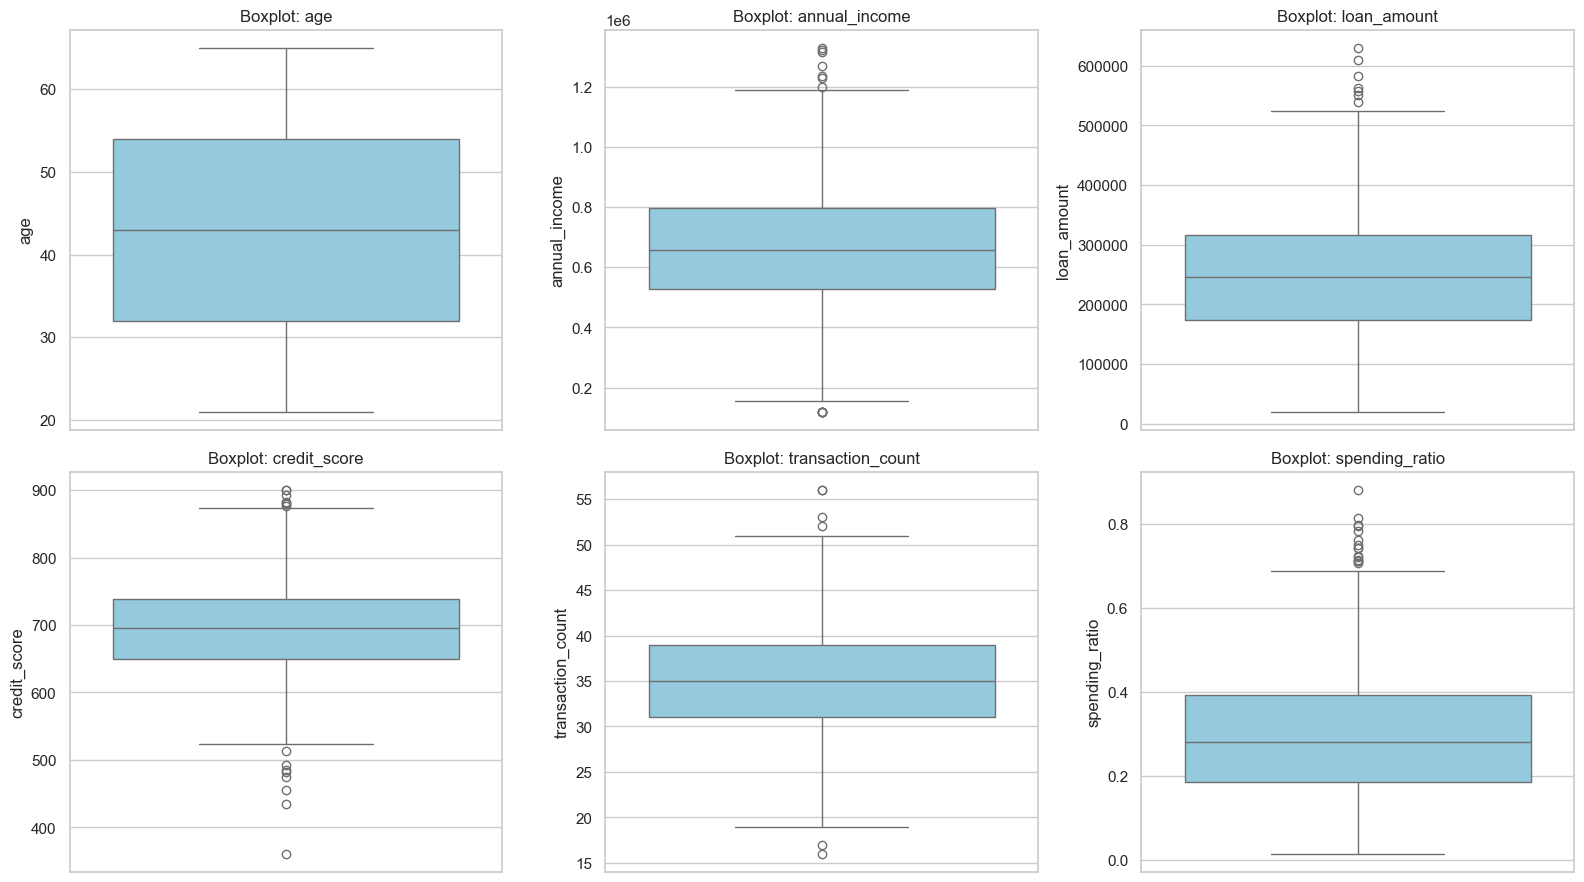

In [8]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, NUMERIC_FEATURES):
    sns.boxplot(y=df[col], ax=ax, color="skyblue")
    ax.set_title(f"Boxplot: {col}")
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()

## 6. IQR method

In [9]:
def calculate_iqr_bounds(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

iqr_rows = []
iqr_masks = {}
for col in NUMERIC_FEATURES:
    lower, upper = calculate_iqr_bounds(df[col].dropna())
    mask = (df[col] < lower) | (df[col] > upper)
    iqr_masks[col] = mask
    iqr_rows.append({
        "feature": col, "lower_bound": lower, "upper_bound": upper,
        "outlier_count": int(mask.sum()),
        "outlier_percentage": mask.mean() * 100
    })

iqr_report = pd.DataFrame(iqr_rows)
display(iqr_report.round(3))

,feature,lower_bound,upper_bound,outlier_count,outlier_percentage
0,age,-1.000,87.000,0,0.0
1,annual_income,127042.709,1196986.261,12,1.2
2,loan_amount,-36882.789,526929.017,7,0.7
3,credit_score,514.177,873.945,15,1.5
4,transaction_count,19.000,51.000,6,0.6
5,spending_ratio,-0.127,0.705,15,1.5


## 7. Z-score method

In [10]:
zscore_rows = []
zscore_masks = {}
for col in NUMERIC_FEATURES:
    mean = df[col].mean()
    std = df[col].std(ddof=0)
    z = (df[col] - mean) / std if std != 0 else pd.Series(0, index=df.index)
    mask = z.abs() > 3
    zscore_masks[col] = mask
    zscore_rows.append({
        "feature": col, "mean": mean, "standard_deviation": std,
        "outlier_count_abs_z_gt_3": int(mask.sum()),
        "outlier_percentage": mask.mean() * 100
    })

zscore_report = pd.DataFrame(zscore_rows)
display(zscore_report.round(3))

,feature,mean,standard_deviation,outlier_count_abs_z_gt_3,outlier_percentage
0,age,43.002,12.651,0,0.0
1,annual_income,660601.833,203409.181,3,0.3
2,loan_amount,249673.919,106618.823,3,0.3
3,credit_score,694.720,72.383,4,0.4
4,transaction_count,35.172,5.992,4,0.4
5,spending_ratio,0.301,0.158,5,0.5


## 8. Compare IQR and Z-score results

In [11]:
comparison = iqr_report[["feature", "outlier_count", "outlier_percentage"]].merge(
    zscore_report[["feature", "outlier_count_abs_z_gt_3", "outlier_percentage"]],
    on="feature", suffixes=("_iqr", "_zscore")
)
comparison = comparison.rename(columns={
    "outlier_count": "iqr_outlier_count",
    "outlier_percentage_iqr": "iqr_outlier_percentage",
    "outlier_count_abs_z_gt_3": "zscore_outlier_count",
    "outlier_percentage_zscore": "zscore_outlier_percentage"
})
display(comparison.round(3))
comparison.to_csv(REPORT_DIR / "day04_method_comparison.csv", index=False)

,feature,iqr_outlier_count,iqr_outlier_percentage,zscore_outlier_count,zscore_outlier_percentage
0,age,0,0.0,0,0.0
1,annual_income,12,1.2,3,0.3
2,loan_amount,7,0.7,3,0.3
3,credit_score,15,1.5,4,0.4
4,transaction_count,6,0.6,4,0.4
5,spending_ratio,15,1.5,5,0.5


## 9. Business-based validation

In [12]:
BUSINESS_RULES = {
    "age": (18, 100),
    "annual_income": (0, 20_000_000),
    "loan_amount": (0, 10_000_000),
    "credit_score": (300, 900),
    "transaction_count": (0, 500),
    "spending_ratio": (0, 1)
}

business_rows = []
for col, (lower, upper) in BUSINESS_RULES.items():
    mask = (df[col] < lower) | (df[col] > upper)
    business_rows.append({
        "feature": col, "business_min": lower, "business_max": upper,
        "violation_count": int(mask.sum()),
        "violation_percentage": mask.mean() * 100
    })

business_report = pd.DataFrame(business_rows)
display(business_report.round(3))
business_report.to_csv(REPORT_DIR / "day04_business_validation_report.csv", index=False)

,feature,business_min,business_max,violation_count,violation_percentage
0,age,18,100,0,0.0
1,annual_income,0,20000000,0,0.0
2,loan_amount,0,10000000,0,0.0
3,credit_score,300,900,0,0.0
4,transaction_count,0,500,0,0.0
5,spending_ratio,0,1,0,0.0


## 10. Capping and Winsorization

In [13]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["default_flag"])
y = df["default_flag"]

train_idx, test_idx = train_test_split(
    df.index, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
train_df = df.loc[train_idx].copy()
test_df = df.loc[test_idx].copy()

threshold_rows = []
for col in NUMERIC_FEATURES:
    lower, upper = calculate_iqr_bounds(train_df[col].dropna())
    threshold_rows.append({
        "feature": col, "train_lower_bound": lower, "train_upper_bound": upper
    })

thresholds = pd.DataFrame(threshold_rows)
display(thresholds.round(3))
thresholds.to_csv(REPORT_DIR / "day04_train_fitted_capping_thresholds.csv", index=False)

def apply_caps(frame, threshold_table):
    result = frame.copy()
    for row in threshold_table.itertuples(index=False):
        result[row.feature] = result[row.feature].clip(
            lower=row.train_lower_bound, upper=row.train_upper_bound
        )
    return result

train_capped = apply_caps(train_df, thresholds)
test_capped = apply_caps(test_df, thresholds)

print("Training rows:", len(train_capped))
print("Testing rows:", len(test_capped))
print("Target unchanged in training:", train_capped["default_flag"].equals(train_df["default_flag"]))
print("Target unchanged in testing:", test_capped["default_flag"].equals(test_df["default_flag"]))

,feature,train_lower_bound,train_upper_bound
0,age,1.500,85.500
1,annual_income,136183.790,1181751.125
2,loan_amount,-28836.883,522101.474
3,credit_score,512.646,880.775
4,transaction_count,19.000,51.000
5,spending_ratio,-0.132,0.699


Training rows: 800
Testing rows: 200
Target unchanged in training: True
Target unchanged in testing: True


## 11. Before-and-after visualization

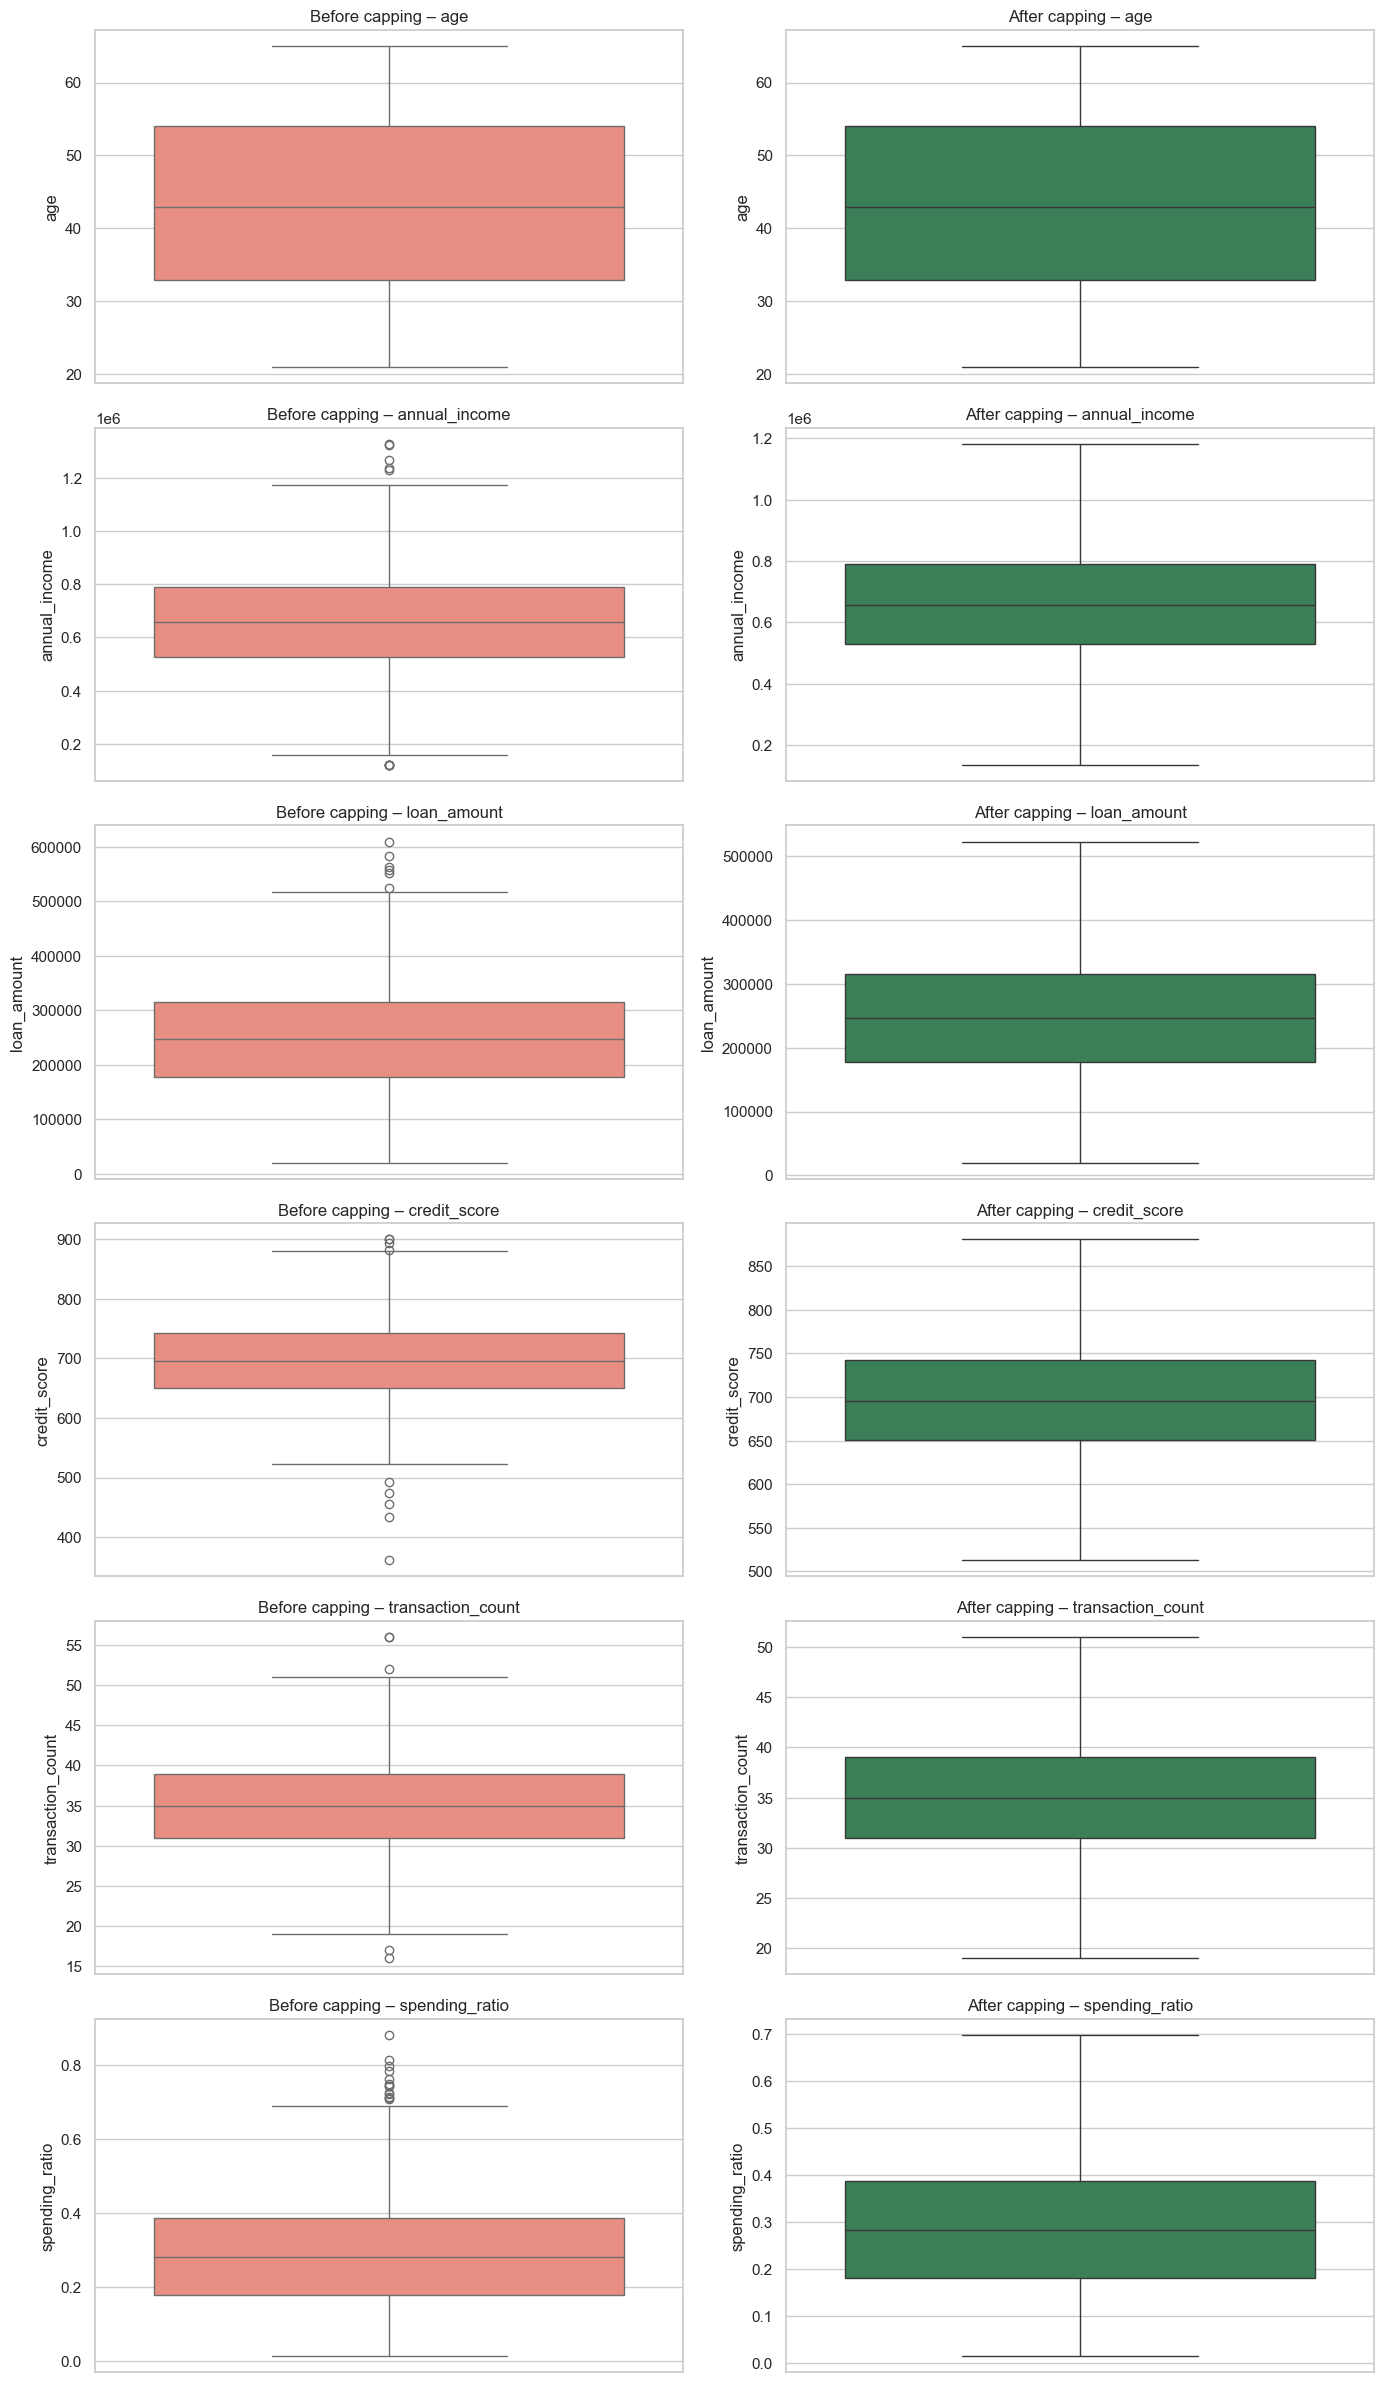

In [14]:
fig, axes = plt.subplots(len(NUMERIC_FEATURES), 2, figsize=(14, 4 * len(NUMERIC_FEATURES)))
for i, col in enumerate(NUMERIC_FEATURES):
    sns.boxplot(y=train_df[col], ax=axes[i, 0], color="salmon")
    axes[i, 0].set_title(f"Before capping – {col}")
    sns.boxplot(y=train_capped[col], ax=axes[i, 1], color="seagreen")
    axes[i, 1].set_title(f"After capping – {col}")
plt.tight_layout()
plt.show()

## 12. Treatment summary and processed dataset

The complete treated dataset below is created using thresholds learned from the training split and applied consistently to the full dataset for the project hand-off. For a real predictive evaluation, retain the separate `train_capped` and `test_capped` objects and do not use the full-data output to evaluate model performance.

The processed CSV preserves identifiers, categories, dates, and the target. Only the six selected numeric features are capped.

In [15]:
full_capped = apply_caps(df, thresholds)

treatment_rows = []
for col in NUMERIC_FEATURES:
    changed = int((df[col] != full_capped[col]).sum())
    treatment_rows.append({
        "feature": col,
        "values_capped": changed,
        "minimum_before": df[col].min(),
        "maximum_before": df[col].max(),
        "minimum_after": full_capped[col].min(),
        "maximum_after": full_capped[col].max()
    })

treatment_report = pd.DataFrame(treatment_rows)
display(treatment_report.round(3))

processed_path = PROCESSED_DIR / "customer_credit_risk_day04_outlier_treated.csv"
treatment_report.to_csv(REPORT_DIR / "day04_outlier_treatment_summary.csv", index=False)
full_capped.to_csv(processed_path, index=False)
print("Processed dataset saved to:", processed_path)

,feature,values_capped,minimum_before,maximum_before,minimum_after,maximum_after
0,age,0,21.000,65.000,21.000,65.000
1,annual_income,13,120000.000,1329472.683,136183.790,1181751.125
2,loan_amount,8,20000.000,629945.104,20000.000,522101.474
3,credit_score,11,360.816,900.000,512.646,880.775
4,transaction_count,6,16.000,56.000,19.000,51.000
5,spending_ratio,15,0.014,0.881,0.014,0.699


Processed dataset saved to: c:\Users\tejpa\OneDrive\Documents\R & W Projects\Data Preparing & Processing\Holistic-data-preparer\data\processed\customer_credit_risk_day04_outlier_treated.csv


## 13. Why we do not automatically remove outliers

Removing rows can:
- Discard valid high-income or high-loan customers.
- Reduce the number of default examples.
- Change the target distribution.
- Introduce selection bias.
- Remove rare but important risk patterns.

Removal may be appropriate only when there is strong evidence of corrupted or impossible records, and the decision is documented with domain experts. For this project, capping is demonstrated as a conservative option, not a universal rule.

## 14. Final validation

We verify the required schema, row count, target values, identifier uniqueness, and that the raw file was not overwritten.

In [16]:
final_df = pd.read_csv(processed_path)
assert final_df.columns.tolist() == EXPECTED_COLUMNS
assert len(final_df) == len(df), "Capping should not remove rows."
assert final_df["customer_id"].is_unique
assert set(final_df["default_flag"].dropna().unique()).issubset({0, 1})
assert raw_path.exists(), "Raw source file must remain available."
assert len(pd.read_csv(raw_path)) == len(raw_df), "Raw row count unexpectedly changed."

validation_summary = pd.DataFrame({
    "check": [
        "Expected columns present and in order",
        "Row count preserved",
        "Customer IDs unique",
        "Target contains only 0/1",
        "Raw dataset file preserved"
    ],
    "passed": [True, len(final_df) == len(df), final_df["customer_id"].is_unique,
               set(final_df["default_flag"].dropna().unique()).issubset({0, 1}),
               raw_path.exists()]
})
display(validation_summary)
validation_summary.to_csv(REPORT_DIR / "day04_final_validation_report.csv", index=False)

,check,passed
0,Expected columns present and in order,True
1,Row count preserved,True
2,Customer IDs unique,True
3,Target contains only 0/1,True
4,Raw dataset file preserved,True
